In [6]:
# === LOAD: locate repo and load `sessions` with all_data_df ===
import sys, pickle
from pathlib import Path
import pandas as pd

# Try to discover the repo root from the current notebook location
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    # fallback to your known absolute path
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

# Make package importable (optional, but matches your pattern)
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

# Optional sanity check for the package
try:
    import importlib; importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

# Default PKL path from your earlier snippet
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"

# Fallback: search for a suitable PKL if the default is missing
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    # pick the most recent
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

with PKL.open("rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions from {PKL}")

# Keep only sessions that actually have non-empty all_data_df
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

# Quick peek
if sessions:
    s0 = sessions[0]
    sid  = getattr(s0, "session_id", "<no id>")
    geno = (getattr(s0, "metadata", {}) or {}).get("genotype", "UNK")
    print(f"Example session: {sid} | genotype={geno}")
    display(s0.all_data_df.head())
else:
    raise RuntimeError("No usable sessions found; check your pickle or preprocessing.")


Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl
Loaded 19 sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl
Usable sessions with all_data_df: 19
Example session: 2024-12-13T12_20_06_bottom_left | genotype=WT


,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset,...,signal_0_zscore_datta,signal_1_dff,signal_1_zscore,signal_1_zscore_datta,signal_2_dff,signal_2_zscore,signal_2_zscore_datta,signal_3_dff,signal_3_zscore,signal_3_zscore_datta
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,69517,WT,True,...,0.284346,-0.456758,-0.635931,-0.340642,-0.342478,-0.795487,-1.066838,-0.565258,-0.636459,-0.953344
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,69518,WT,False,...,0.458511,-0.457280,-0.642150,-0.387259,-0.341230,-0.789986,-1.007153,-0.565216,-0.636034,-0.862807
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,69519,WT,False,...,0.632677,-0.457802,-0.648369,-0.433876,-0.339982,-0.784485,-0.947469,-0.565174,-0.635609,-0.772271
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,69520,WT,False,...,0.806842,-0.458323,-0.654588,-0.480492,-0.338734,-0.778983,-0.887785,-0.565133,-0.635184,-0.681734
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,69521,WT,False,...,1.072744,-0.457493,-0.644689,-0.433324,-0.338548,-0.778165,-0.890066,-0.563833,-0.621913,-0.537591


Scanning 19 sessions...
[WT | DLS-R] Excluded 1290/4482 trials (28.8%). Full-NaN: 1289, Partial-NaN: 1
[KI | VS-R] Excluded 260/6552 trials (4.0%). Full-NaN: 254, Partial-NaN: 6
[KI | DLS-L] Excluded 99/5688 trials (1.7%). Full-NaN: 99, Partial-NaN: 0
[KI | DMS-L] Excluded 420/6431 trials (6.5%). Full-NaN: 418, Partial-NaN: 2
[KI | DLS-R] Excluded 5590/6431 trials (86.9%). Full-NaN: 5590, Partial-NaN: 0
[KI | VS-L] Excluded 421/5775 trials (7.3%). Full-NaN: 415, Partial-NaN: 6
[KI | DMS-R] Excluded 361/5775 trials (6.3%). Full-NaN: 358, Partial-NaN: 3
Genotypes: ['KI', 'WT']
Regions: ['DLS', 'DMS', 'VS']

--- Plotting: L Hemisphere | G Channel ---


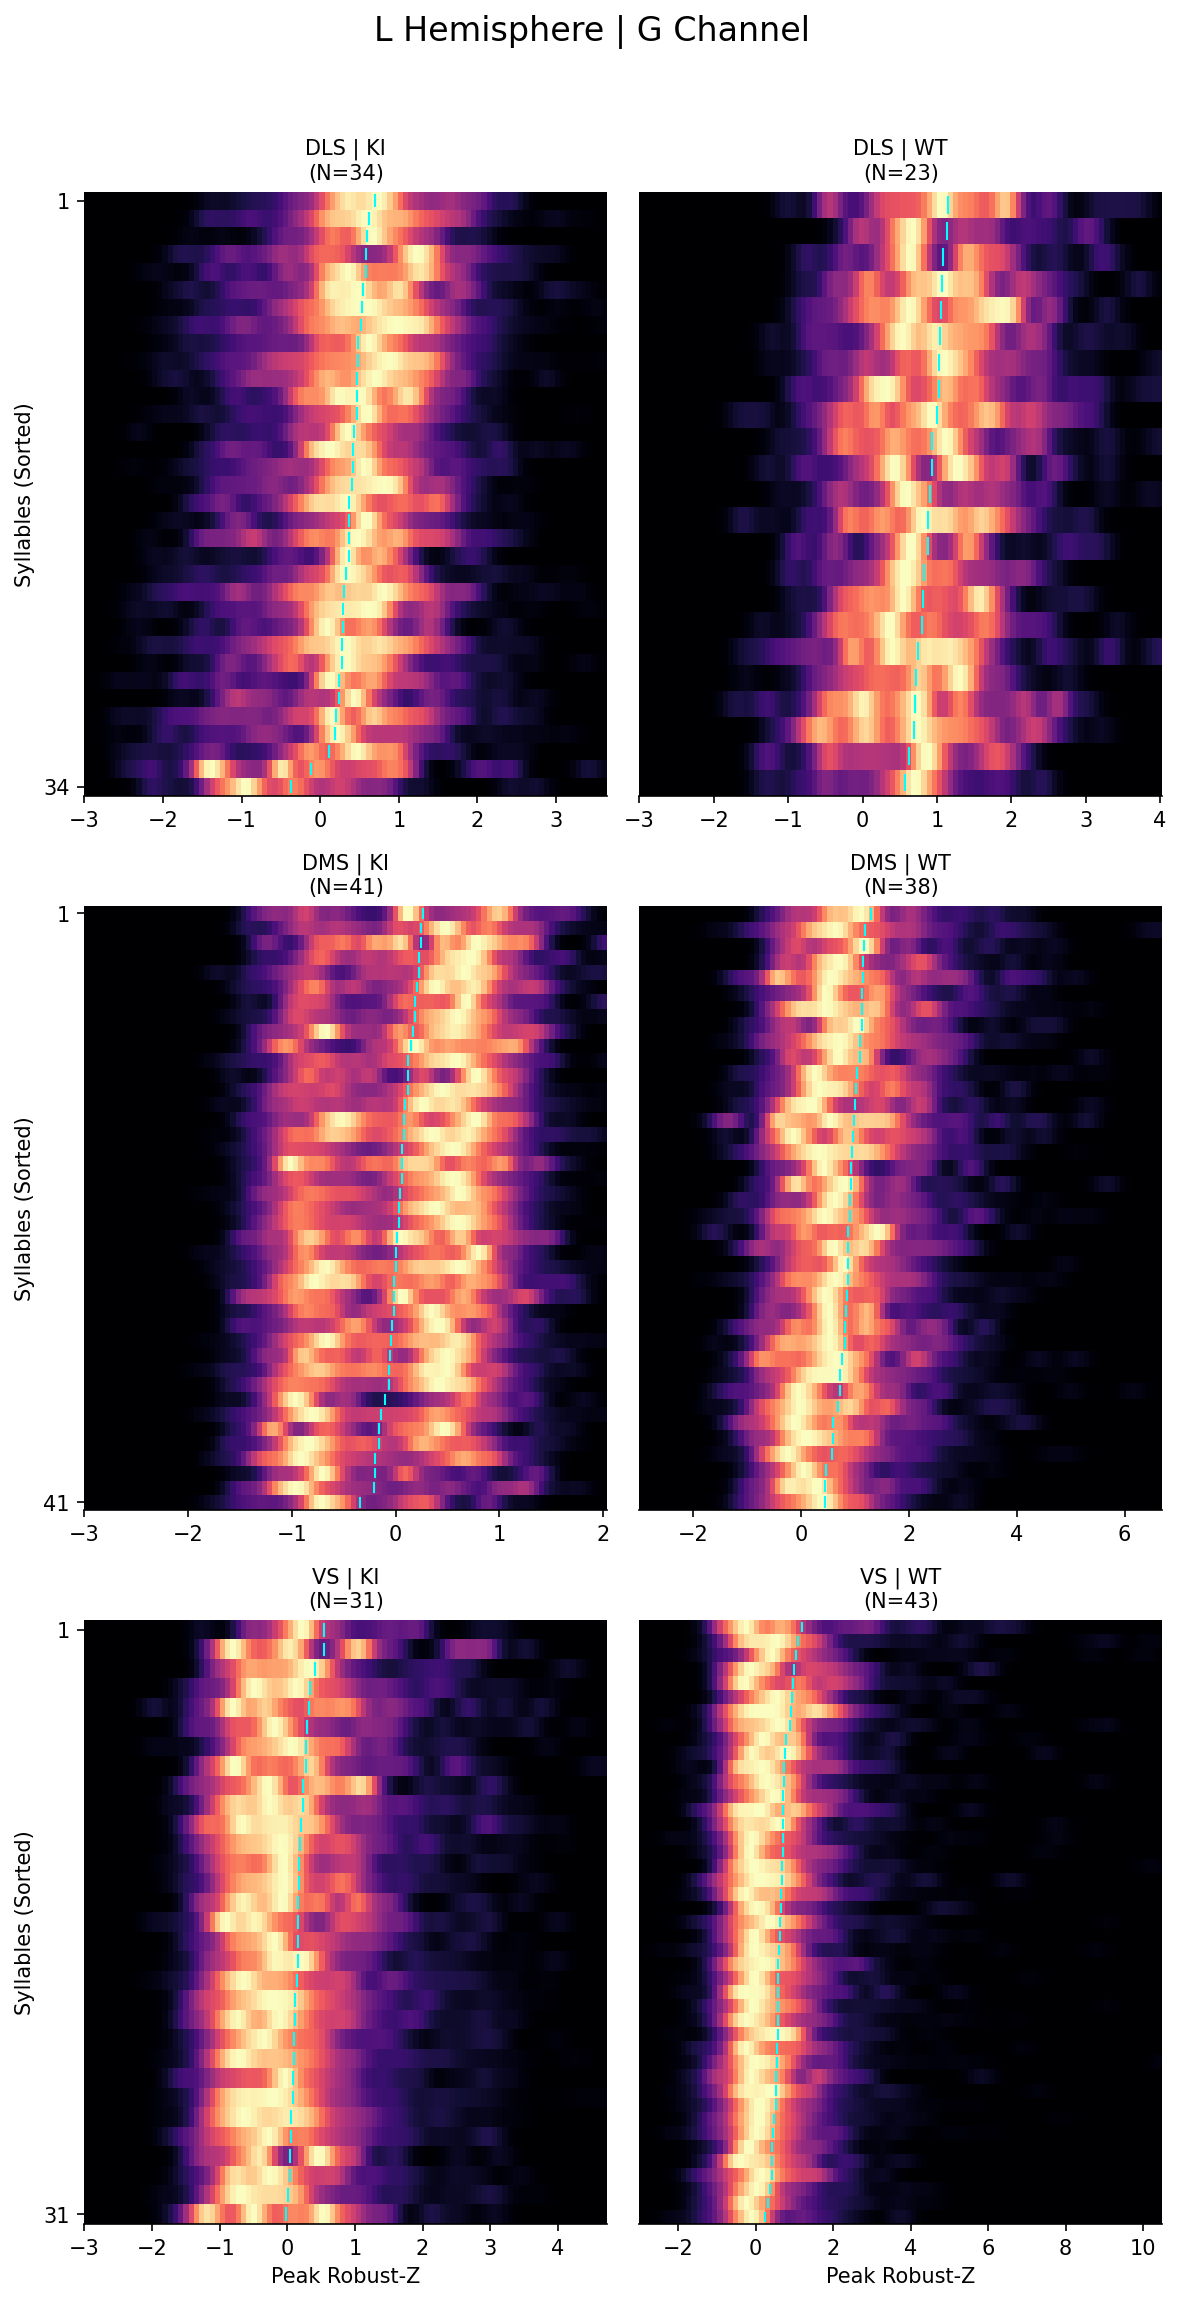


--- Plotting: R Hemisphere | G Channel ---


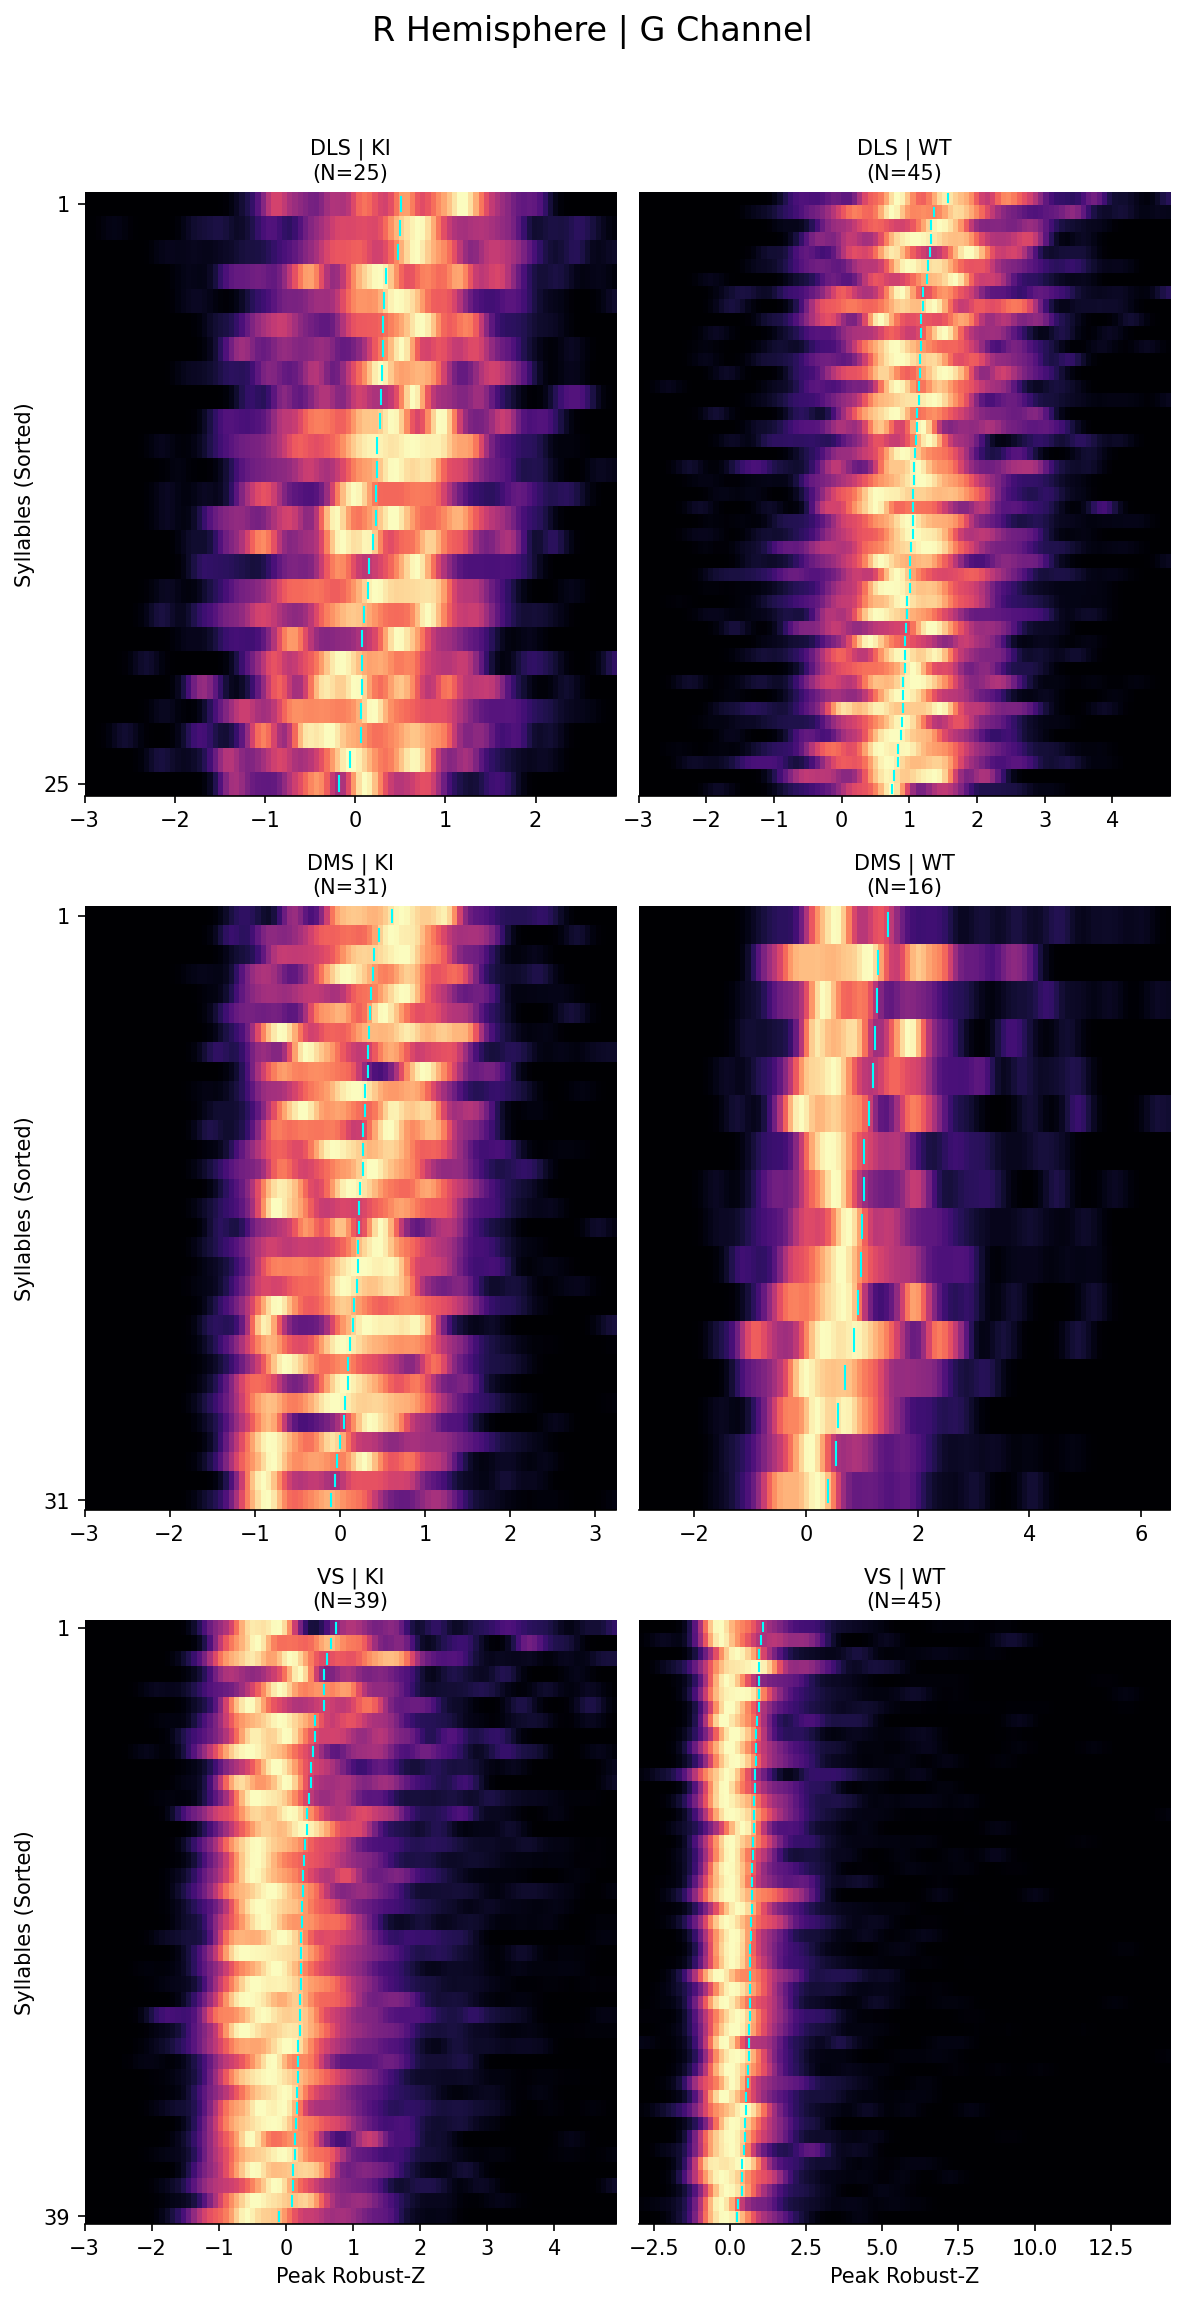

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================
# --- BOUNDARIES ---
X_LOWER_BOUND = -3.0        
X_UPPER_QUANTILE = 0.999    

# --- VISUALIZATION ---
BIN_COUNT = 100            
CMAP = "magma"
SMOOTHING_SIGMA = 2       
ROW_WISE_NORM = True       

# --- FILTERS ---
WINDOW_SECONDS = 0.3       
MIN_TRIALS = 50           
REMOVE_IMMEDIATE = True    
KEEP_TOP_N_SYLLABLES = 50  

# --- NORMALIZATION ---
USE_ROBUST_Z = True        

# --- DATA ---
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}

# --- SEARCH SPACE (The Update) ---
TARGET_COLORS = ["G"]          # Green, Red
TARGET_HEMISPHERES = ["L", "R"]     # Left, Right

# ==========================================
# 2. DATA AGGREGATION
# ==========================================
# Structure: data_buckets[geno][region][hemi][color] -> list of dataframes
import re 

def clean_region_name(raw_name):
    """Converts 'L-DLS' -> 'DLS', 'R-VS' -> 'VS'"""
    if not raw_name: return "UNK"
    # Remove L- or R- prefix (case insensitive) followed by any separator
    s = re.sub(r"^[LRlr][\s\-_]+", "", str(raw_name))
    return s.strip().upper()

data_buckets = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list))))

print(f"Scanning {len(sessions)} sessions...")

for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate & Onsets
    if "SystemTimestamp" in df.columns and len(df) > 1:
        # [FIX] Drop NaNs before diffing to avoid fs = NaN
        valid_ts = df["SystemTimestamp"].dropna().to_numpy()
        if len(valid_ts) > 1:
            dt = np.nanmedian(np.diff(valid_ts))
            # Protect against divide-by-zero or garbage dt
            fs = 1 / dt if dt > 0 else 30.0
        else:
            fs = 30.0
    else: 
        fs = 30.0

    window_frames = int(WINDOW_SECONDS * fs)
    
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    syllable_array = df["syllable"].to_numpy()
    
    
    # Signal Extraction Loop
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # ... [Metadata Extraction & Cleaning Code] ...
        raw_region = info.get("brain_reg", "UNK")
        region = clean_region_name(raw_region) 
        hemi = str(info.get("hemisphere", "")).upper()
        if not hemi or hemi == "UNK":
            if str(raw_region).upper().startswith("L"): hemi = "L"
            elif str(raw_region).upper().startswith("R"): hemi = "R"
        
        color = str(info.get("orig_letter", "")).upper()
        if not color and "fiber_num" in info:
            color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
            
        # --- FILTERS ---
        if region in IGNORE_REGIONS or region == "UNK": continue
        if hemi not in TARGET_HEMISPHERES: continue
        if color not in TARGET_COLORS: continue
            
        # Prefer Raw DFF
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        if col_name is None: continue

        signal_data = df[col_name].to_numpy()
        
        # Robust Baseline
        if USE_ROBUST_Z and "dff" in col_name:
            sess_med = np.nanmedian(signal_data)
            sess_mad = np.nanmedian(np.abs(signal_data - sess_med)) * 1.4826
            if sess_mad == 0: sess_mad = 1.0
        
        current_peaks = []
        
        # --- COUNTERS ---
        n_total = 0
        n_nan_partial = 0
        n_nan_full = 0
        
        for idx in onset_indices:
            if idx + window_frames >= len(signal_data): continue
            
            n_total += 1
            segment = signal_data[idx : idx + window_frames]
            
            # --- NAN CHECK ---
            is_nan = np.isnan(segment)
            if is_nan.any():
                if is_nan.all():
                    n_nan_full += 1
                else:
                    n_nan_partial += 1
                continue # Skip this trial
            # -----------------

            peak_val = np.max(segment)
            peak_frame = np.argmax(segment)
            peak_time = peak_frame / fs 
            if REMOVE_IMMEDIATE and peak_time < 0.025: continue

            if USE_ROBUST_Z and "dff" in col_name:
                final_val = (peak_val - sess_med) / sess_mad
            else:
                final_val = peak_val

            current_peaks.append({
                "syllable": syllable_array[idx],
                "peak": final_val,
                "peak_time": peak_time
            })
            
        # --- LOGGING ---
        n_excluded = n_nan_full + n_nan_partial
        if n_excluded > 0:
            pct = (n_excluded / n_total) * 100
            print(f"[{geno} | {region}-{hemi}] Excluded {n_excluded}/{n_total} trials ({pct:.1f}%). "
                  f"Full-NaN: {n_nan_full}, Partial-NaN: {n_nan_partial}")

        if current_peaks:
            data_buckets[geno][region][hemi][color].append(pd.DataFrame(current_peaks))

# ==========================================
# 3. PLOTTING (Iterative Generation)
# ==========================================
unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

print(f"Genotypes: {unique_genos}")
print(f"Regions: {unique_regions}")

# We will generate ONE FIGURE per (Hemisphere x Color) combination
# Each figure will be a grid of (Region x Genotype)

for color in TARGET_COLORS:
    for hemi in TARGET_HEMISPHERES:
        
        print(f"\n--- Plotting: {hemi} Hemisphere | {color} Channel ---")
        
        # Check if data exists for this combo
        has_data = False
        for g in unique_genos:
            for r in unique_regions:
                if data_buckets[g][r][hemi][color]:
                    has_data = True
        
        if not has_data:
            print("   Skipping (No Data)")
            continue

        fig, axes = plt.subplots(
            nrows=len(unique_regions), ncols=len(unique_genos), 
            figsize=(4 * len(unique_genos), 5 * len(unique_regions)),
            dpi=150, sharex=False, sharey=False
        )
        
        # Array shape handling
        if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
        elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
        elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

        for r_idx, region in enumerate(unique_regions):
            for c_idx, geno in enumerate(unique_genos):
                ax = axes[r_idx, c_idx]
                chunks = data_buckets[geno][region][hemi][color]
                
                if not chunks:
                    ax.text(0.5, 0.5, "No Data", ha='center', va='center', transform=ax.transAxes)
                    ax.set_title(f"{region} | {geno}")
                    continue
                    
                feat_df = pd.concat(chunks, ignore_index=True)
                
                # --- FILTER 1: Counts ---
                counts = feat_df["syllable"].value_counts()
                valid = counts[counts >= MIN_TRIALS].index
                feat_df = feat_df[feat_df["syllable"].isin(valid)]
                
                # --- FILTER 2: Center-Cut ---
                if KEEP_TOP_N_SYLLABLES and len(feat_df) > 0:
                    global_med = feat_df["peak_time"].median()
                    syll_meds = feat_df.groupby("syllable")["peak_time"].median()
                    best_sylls = (syll_meds - global_med).abs().nsmallest(KEEP_TOP_N_SYLLABLES).index
                    feat_df = feat_df[feat_df["syllable"].isin(best_sylls)]

                # --- SORTING ---
                syll_means = feat_df.groupby("syllable")["peak"].mean()
                sorting = syll_means.sort_values(ascending=False).index.tolist()
                
                if not sorting:
                    ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center', transform=ax.transAxes)
                    continue

                # --- CALCULATE BOUNDARIES ---
                view_min = X_LOWER_BOUND
                view_max = feat_df["peak"].quantile(X_UPPER_QUANTILE)
                if view_max <= view_min: view_max = view_min + 1.0
                
                edges = np.linspace(view_min, view_max, BIN_COUNT + 1)
                
                # --- DENSITY ---
                density_matrix = []
                mean_vals = []
                
                for syll in sorting:
                    vals = feat_df.loc[feat_df["syllable"] == syll, "peak"]
                    hist, _ = np.histogram(vals, bins=edges, density=True)
                    
                    hist = gaussian_filter1d(hist, sigma=SMOOTHING_SIGMA)
                    
                    if ROW_WISE_NORM and hist.max() > 0: 
                        hist /= hist.max()
                        
                    density_matrix.append(hist)
                    mean_vals.append(vals.mean())
                    
                # --- PLOT ---
                im = ax.imshow(
                    np.array(density_matrix), 
                    aspect="auto",
                    extent=(view_min, view_max, len(sorting), 0),
                    vmax=1.0 if ROW_WISE_NORM else None, 
                    cmap=CMAP,
                    interpolation="nearest"
                )
                
                pad = 0.2
                for i, mu in enumerate(mean_vals):
                    if view_min <= mu <= view_max:
                        ax.plot([mu, mu], [i + pad, i + 1 - pad], color="cyan", linewidth=1.0)
                
                ax.set_title(f"{region} | {geno}\n(N={len(sorting)})", fontsize=10)
                if c_idx == 0:
                    ax.set_ylabel("Syllables (Sorted)")
                    ax.set_yticks([0.5, len(sorting)-0.5])
                    ax.set_yticklabels(["1", str(len(sorting))])
                else: ax.set_yticks([])
                
                if r_idx == len(unique_regions)-1: 
                    ax.set_xlabel(f"Peak {'Robust-Z' if USE_ROBUST_Z else 'Z-Score'}")
                    
                sns.despine(ax=ax, left=True, bottom=False)

        # Super Title
        plt.suptitle(f"{hemi} Hemisphere | {color} Channel", y=1.02, fontsize=16)
        plt.tight_layout()
        plt.show()